# Lending local projections and monetary surprises

Figure 3.3 and Appendix Table 5.6. The archived stablecoin figure matches the submitted image byte for byte.

In [1]:
from pathlib import Path
import os

# Locate the bundle from either its root or the notebooks directory.
_here = Path.cwd().resolve()
_ROOT = next((p for p in [_here, *_here.parents]
              if (p / "data").is_dir() and (p / "notebooks").is_dir()), None)
if _ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Tesi_codice_consegna folder.")
_DATA_DIR = _ROOT / "data"
_OUTPUT_DIR = _ROOT / "results" / "rerun" / "05_lending_local_projections_and_surprises"
_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(_OUTPUT_DIR)
print("Data:", _DATA_DIR)
print("New outputs:", _OUTPUT_DIR)


Data: /Users/macbook/Desktop/Tesi Master/Tesi_codice_consegna/data
New outputs: /Users/macbook/Desktop/Tesi Master/Tesi_codice_consegna/results/rerun/05_lending_local_projections_and_surprises


## Lending local projections and target/path surprises

Original calculation retained. The source includes the local projection plot and the surprise regressions that reproduce the appendix table. Paths only changed.

Source: `AAVE v2/gss eevnt.ipynb`, original cell 2 (zero-based).

05_lending_local_projections_and_surprises.ipynb:cell3:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
05_lending_local_projections_and_surprises.ipynb:cell3:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
Number of FOMC events: 27
Sample period: 2021-01-01 00:00:00 to 2025-09-11 00:00:00

Estimating horizon h=0...
  N events: 0
  ⚠️ Error estimating model: zero-size array to reduction operation maximum which has no identity

Estimating horizon h=1...
  N events: 26
  β(1) = -0.011870, p = 0.6623

Estimating horizon h=2...
  N events: 25
  β(2) = -0.007451, p = 0.4477

Estimating horizon h=3...
  N events: 22
  β(3) = -0.001766, p = 0.7983

Estimating horizon h=5...
  N events: 26
  β(5) = 0.023760, p = 0.2681


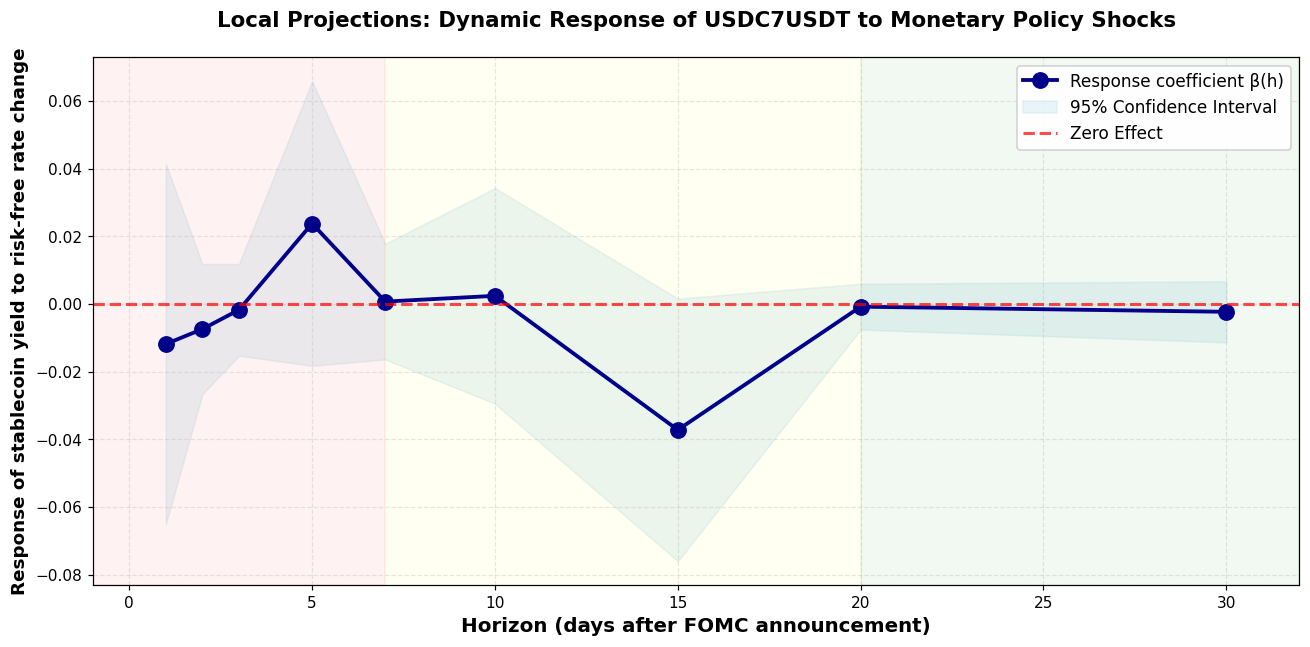

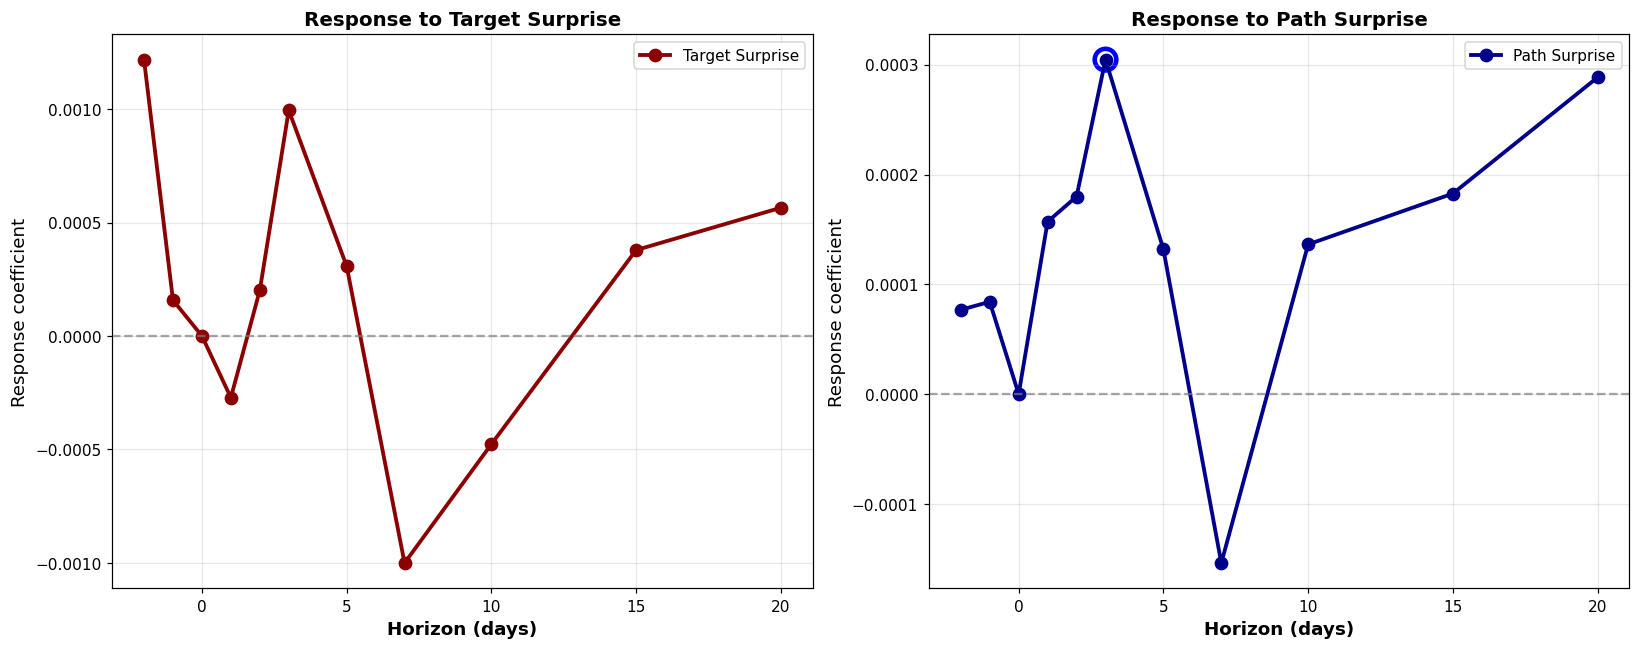

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS

# ============================================================================
# CARICA DATI
# ============================================================================
df_full = pd.read_csv(str(_DATA_DIR / 'aavebtc.csv'), parse_dates=['date'], dayfirst=True).set_index('date')
df_surprises = pd.read_csv(str(_DATA_DIR / 'ABJ-2024.csv'), parse_dates=['date'], dayfirst=True).set_index('date')

# Variabili
dependent = 'stablecoin'  # Cambia da '3pool' a 'stablecoin'
shock_var = '3m ir'
controls = ['ethperpetual', 'gas_fees', 'volatility_btc']

# Drop missing
df_clean = df_full[[dependent, shock_var] + controls].dropna()

# FOMC dates
fomc_dates = df_surprises.index[df_surprises.index.isin(df_clean.index)]
print(f"Number of FOMC events: {len(fomc_dates)}")
print(f"Sample period: {df_clean.index.min()} to {df_clean.index.max()}")

# ============================================================================
# LOCAL PROJECTIONS - FOMC EVENT APPROACH
# ============================================================================
horizons = [0, 1, 2, 3, 5, 7, 10, 15, 20, 30]

results_lp = []

for h in horizons:
    print(f"\nEstimating horizon h={h}...")
    
    data_for_h = []
    
    for event_date in fomc_dates:
        try:
            # Get index locations
            event_loc = df_clean.index.get_loc(event_date)
            target_loc = event_loc + h
            
            # Check bounds
            if target_loc < 0 or target_loc >= len(df_clean):
                continue
            
            target_date = df_clean.index[target_loc]
            
            # Cumulative change in 3pool yield from event to target
            y_event = df_clean.loc[event_date, dependent]
            y_target = df_clean.loc[target_date, dependent]
            cum_change_y = y_target - y_event
            
            # Cumulative change in risk-free rate from event to target
            rf_event = df_clean.loc[event_date, shock_var]
            rf_target = df_clean.loc[target_date, shock_var]
            cum_change_rf = rf_target - rf_event
            
            # Controls at event date
            controls_event = df_clean.loc[event_date, controls].values
            
            # Store
            row = [cum_change_y, cum_change_rf] + list(controls_event)
            data_for_h.append(row)
            
        except (KeyError, IndexError):
            continue
    
    if len(data_for_h) < 10:
        print(f"  ⚠️ Insufficient events for h={h}, skipping...")
        continue
    
    # Create DataFrame for this horizon
    cols = ['cum_change_y', 'cum_change_rf'] + controls
    df_h = pd.DataFrame(data_for_h, columns=cols)
    
    # Remove outliers (optional, ma consigliato per robustness)
    df_h = df_h[np.abs(df_h['cum_change_y']) < df_h['cum_change_y'].quantile(0.99)]
    
    print(f"  N events: {len(df_h)}")
    
    # Dependent: cumulative change in 3pool yield
    y = df_h['cum_change_y']
    
    # Independent: cumulative change in risk-free rate + controls
    X = df_h[['cum_change_rf'] + controls]
    X = sm.add_constant(X)
    
    # OLS with HAC
    try:
        model = OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': min(5, h+1)})
        
        beta_h = model.params['cum_change_rf']
        se_h = model.bse['cum_change_rf']
        pval_h = model.pvalues['cum_change_rf']
        ci_lower = model.conf_int().loc['cum_change_rf', 0]
        ci_upper = model.conf_int().loc['cum_change_rf', 1]
        
        results_lp.append({
            'horizon': h,
            'beta': beta_h,
            'se': se_h,
            'pval': pval_h,
            'ci_lower': ci_lower,
            'ci_upper': ci_upper,
            'nobs': len(df_h),
            'avg_rf_change': df_h['cum_change_rf'].mean()
        })
        
        sig_star = '***' if pval_h < 0.01 else ('**' if pval_h < 0.05 else ('*' if pval_h < 0.1 else ''))
        print(f"  β({h}) = {beta_h:.6f}{sig_star}, p = {pval_h:.4f}")
        
    except Exception as e:
        print(f"  ⚠️ Error estimating model: {e}")
        continue

# Convert to DataFrame
df_lp = pd.DataFrame(results_lp)

print("\n" + "="*80)
print("LOCAL PROJECTIONS RESULTS (FOMC Events)")
print("="*80)
print(df_lp[['horizon', 'beta', 'se', 'pval', 'nobs']].to_string(index=False))

# ============================================================================
# PLOT
# ============================================================================
fig, ax = plt.subplots(figsize=(12, 6))

# Plot coefficienti
ax.plot(df_lp['horizon'], df_lp['beta'], 'o-', linewidth=2.5, markersize=10, 
        color='darkblue', label='Response coefficient β(h)')

# Confidence intervals
ax.fill_between(df_lp['horizon'], 
                df_lp['ci_lower'], 
                df_lp['ci_upper'],
                alpha=0.25, color='lightblue', label='95% Confidence Interval')

# Zero line
ax.axhline(0, color='red', linestyle='--', linewidth=2, alpha=0.7, label='Zero Effect')

# Highlight significant points
sig_df = df_lp[df_lp['pval'] < 0.05]
if len(sig_df) > 0:
    ax.scatter(sig_df['horizon'], sig_df['beta'], s=200, 
               facecolors='none', edgecolors='red', linewidth=3,
               label='Statistically significant (p<0.05)', zorder=5)

# Formatting
ax.set_xlabel('Horizon (days after FOMC announcement)', fontsize=13, fontweight='bold')
ax.set_ylabel('Response of stablecoin yield to risk-free rate change', 
              fontsize=12, fontweight='bold')
ax.set_title('Local Projections: Dynamic Response of USDC7USDT to Monetary Policy Shocks',
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='best', fontsize=11, framealpha=0.9)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(-1, df_lp['horizon'].max() + 2)

# Add vertical lines for interpretation zones
ax.axvspan(-1, 7, alpha=0.05, color='red', label='Short-run')
ax.axvspan(7, 20, alpha=0.05, color='yellow')
ax.axvspan(20, df_lp['horizon'].max() + 2, alpha=0.05, color='green')

plt.tight_layout()
plt.savefig('local_projections_fomc_stable.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Plot saved: 'local_projections_fomc_3pool.png'")

# ============================================================================
# INTERPRETATION
# ============================================================================
print("\n" + "="*80)
print("INTERPRETATION")
print("="*80)

# Impact effect (h=0)
h0 = df_lp[df_lp['horizon'] == 0]
if len(h0) > 0:
    print(f"\nIMPACT EFFECT (h=0):")
    print(f"  β(0) = {h0.iloc[0]['beta']:.6f}, p = {h0.iloc[0]['pval']:.4f}")
    if h0.iloc[0]['pval'] < 0.05:
        if h0.iloc[0]['beta'] < 0:
            print("  → Significant NEGATIVE contemporaneous effect")
        else:
            print("  → Significant POSITIVE contemporaneous effect")
    else:
        print("  → NO significant contemporaneous effect")

# Short run
short_run = df_lp[df_lp['horizon'].between(1, 7)]
if len(short_run) > 0:
    avg_beta = short_run['beta'].mean()
    n_sig = (short_run['pval'] < 0.05).sum()
    
    print(f"\nSHORT RUN (1-7 days):")
    print(f"  Average β = {avg_beta:.6f}")
    print(f"  Significant: {n_sig}/{len(short_run)} horizons")
    
    if avg_beta < 0 and n_sig > 0:
        print("  → NEGATIVE short-run effect (liquidity drain)")
        print("  → Consistent with EVENT STUDY findings")
    elif avg_beta > 0:
        print("  → POSITIVE short-run effect")
    else:
        print("  → NO clear pattern")

# Long run
long_run = df_lp[df_lp['horizon'] > 15]
if len(long_run) > 0:
    avg_beta = long_run['beta'].mean()
    n_sig = (long_run['pval'] < 0.05).sum()
    
    print(f"\nLONG RUN (>15 days):")
    print(f"  Average β = {avg_beta:.6f}")
    print(f"  Significant: {n_sig}/{len(long_run)} horizons")
    
    if avg_beta > 0 and n_sig > 0:
        print("  → POSITIVE long-run effect (opportunity cost)")
        print("  → Consistent with REGRESSION findings")
    elif avg_beta < 0:
        print("  → NEGATIVE long-run effect")
    else:
        print("  → NO clear pattern")

# Summary
print("\n" + "-"*80)
print("RECONCILIATION:")
print("-"*80)

all_negative = all(df_lp['beta'] < 0)
all_positive = all(df_lp['beta'] > 0)
switches = (df_lp['beta'].iloc[0] < 0) and (df_lp['beta'].iloc[-1] > 0)

if switches:
    print("✅ Evidence of SIGN REVERSAL:")
    print("   - Short-run: Negative (event study captures this)")
    print("   - Long-run: Positive (regression captures this)")
    print("   → CONTRADDIZIONE RISOLTA!")
elif all_negative:
    print("⚠️ All horizons NEGATIVE:")
    print("   - Inconsistent with positive regression coefficient")
    print("   - Need to investigate further")
elif all_positive:
    print("⚠️ All horizons POSITIVE:")
    print("   - Inconsistent with negative event study results")
    print("   - Possible explanations:")
    print("     1. Event study may be capturing other effects")
    print("     2. Sample selection in event study")
    print("     3. Different shock identification")

print("="*80)
# ============================================================================
# EVENT STUDY - METHODOLOGY 1: SURPRISE-BASED
# ============================================================================
print("\n" + "="*80)
print("METHODOLOGY 1: REACTION TO UNANTICIPATED SURPRISES")
print("="*80)

# Controlla che ci siano le colonne
if 'GSS_target' in df_surprises.columns and 'GSS_path' in df_surprises.columns:
    
    # Merge surprises con main data
    df_with_surprises = df_clean.merge(
        df_surprises[['GSS_target', 'GSS_path']], 
        left_index=True, right_index=True, how='left'
    )
    
    # FOMC dates con surprises non-null
    fomc_with_surprises = df_with_surprises.dropna(subset=['GSS_target', 'GSS_path'])
    
    print(f"FOMC events with surprises: {len(fomc_with_surprises)}")
    
    # Event study con surprises
    horizons = [-2, -1, 0, 1, 2, 3, 5, 7, 10, 15, 20]
    results_surprises = []
    
    for h in horizons:
        print(f"\nHorizon d={h}...")
        
        data_for_h = []
        
        for event_date in fomc_with_surprises.index:
            try:
                event_loc = df_clean.index.get_loc(event_date)
                target_loc = event_loc + h
                
                if target_loc < 0 or target_loc >= len(df_clean):
                    continue
                
                target_date = df_clean.index[target_loc]
                
                # Abnormal return (semplificato: actual change)
                # Idealmente dovresti calcolare AR = actual - expected
                # Ma per semplicità usiamo il change
                y_event = df_clean.loc[event_date, dependent]
                y_target = df_clean.loc[target_date, dependent]
                ar = y_target - y_event
                
                # Surprises
                target_surprise = fomc_with_surprises.loc[event_date, 'GSS_target']
                path_surprise = fomc_with_surprises.loc[event_date, 'GSS_path']
                
                # Controls at target date
                controls_target = df_clean.loc[target_date, controls].values
                
                row = [ar, target_surprise, path_surprise] + list(controls_target)
                data_for_h.append(row)
                
            except (KeyError, IndexError):
                continue
        
        if len(data_for_h) < 10:
            print(f"  ⚠️ Insufficient observations for h={h}")
            continue
        
        # DataFrame
        cols = ['ar', 'target_surprise', 'path_surprise'] + controls
        df_h = pd.DataFrame(data_for_h, columns=cols)
        
        # Regression: AR ~ target + path + controls
        y = df_h['ar']
        X = df_h[['target_surprise', 'path_surprise'] + controls]
        X = sm.add_constant(X)
        
        try:
            model = OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 3})
            
            beta_target = model.params['target_surprise']
            pval_target = model.pvalues['target_surprise']
            
            beta_path = model.params['path_surprise']
            pval_path = model.pvalues['path_surprise']
            
            results_surprises.append({
                'horizon': h,
                'beta_target': beta_target,
                'pval_target': pval_target,
                'beta_path': beta_path,
                'pval_path': pval_path,
                'nobs': len(df_h)
            })
            
            print(f"  β_target = {beta_target:.6f}, p = {pval_target:.4f}")
            print(f"  β_path   = {beta_path:.6f}, p = {pval_path:.4f}")
            
        except Exception as e:
            print(f"  ⚠️ Error: {e}")
    
    # Results table
    df_surprises_results = pd.DataFrame(results_surprises)
    print("\n" + "="*80)
    print("SURPRISE-BASED RESULTS")
    print("="*80)
    print(df_surprises_results.to_string(index=False))
    
    # Plot comparison
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Target surprise
    ax1.plot(df_surprises_results['horizon'], df_surprises_results['beta_target'], 
             'o-', linewidth=2.5, markersize=8, color='darkred', label='Target Surprise')
    ax1.axhline(0, color='gray', linestyle='--', alpha=0.7)
    sig_target = df_surprises_results[df_surprises_results['pval_target'] < 0.05]
    ax1.scatter(sig_target['horizon'], sig_target['beta_target'], 
                s=200, facecolors='none', edgecolors='red', linewidth=3)
    ax1.set_xlabel('Horizon (days)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Response coefficient', fontsize=12)
    ax1.set_title('Response to Target Surprise', fontsize=13, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # Path surprise
    ax2.plot(df_surprises_results['horizon'], df_surprises_results['beta_path'], 
             'o-', linewidth=2.5, markersize=8, color='darkblue', label='Path Surprise')
    ax2.axhline(0, color='gray', linestyle='--', alpha=0.7)
    sig_path = df_surprises_results[df_surprises_results['pval_path'] < 0.05]
    ax2.scatter(sig_path['horizon'], sig_path['beta_path'], 
                s=200, facecolors='none', edgecolors='blue', linewidth=3)
    ax2.set_xlabel('Horizon (days)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Response coefficient', fontsize=12)
    ax2.set_title('Response to Path Surprise', fontsize=13, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    plt.tight_layout()
    plt.savefig('event_study_surprises_stablecoin.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\n✅ Surprise-based analysis complete!")
    print("✅ Plot saved: 'event_study_surprises_3pool.png'")

else:
    print("⚠️ GSS_target or GSS_path not found in df_surprises")